In [1]:
import sys
PYTHON_PATH = sys.executable
PYTHON_PATH

'/home/jovyan/.mlspace/envs/gigachat_7b_moe/bin/python'

In [2]:
!nvidia-smi

Thu Mar  7 13:57:21 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.54.03              Driver Version: 535.54.03    CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A100-SXM4-80GB          On  | 00000000:89:00.0 Off |                    0 |
| N/A   26C    P0              58W / 400W |      4MiB / 81920MiB |      0%      Default |
|                                         |                      |             Disabled |
+-----------------------------------------+----------------------+--

In [3]:
# !$PYTHON_PATH -m pip uninstall -y transformers
!$PYTHON_PATH -m pip install --upgrade transformers seaborn
!$PYTHON_PATH -m pip install --upgrade accelerate bitsandbytes
# !pip install omegaconf dill
# !pip install termcolor


[notice] A new release of pip is available: 23.3.1 -> 23.3.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 23.3.1 -> 23.3.2
[notice] To update, run: pip install --upgrade pip


In [3]:
sys.path

['/home/jovyan/elluran/moe/case-study',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python39.zip',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/lib-dynload',
 '',
 '/home/jovyan/.local/lib/python3.9/site-packages',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/site-packages',
 '/home/jovyan/shares/SR004.nfs2/dtitov/megablocks',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/site-packages/stanford_stk-0.0.6-py3.9.egg',
 '/home/jovyan/shares/SR004.nfs2/dtitov/grouped_gemm']

In [2]:
try:
    sys.path.remove('/home/jovyan/.local/lib/python3.9/site-packages')
except:
    ...

sys.path

['/home/jovyan/elluran/moe/case-study',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python39.zip',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/lib-dynload',
 '',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/site-packages',
 '/home/jovyan/shares/SR004.nfs2/dtitov/megablocks',
 '/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/site-packages/stanford_stk-0.0.6-py3.9.egg',
 '/home/jovyan/shares/SR004.nfs2/dtitov/grouped_gemm']

In [3]:
sys.path.insert(0, '/home/jovyan/.imgenv-vmamedov-work-0/lib/python3.9/site-packages')

In [4]:
sys.path.insert(0, '/home/jovyan/vmamedov/llm-foundry-moe/sber_notebooks')

In [5]:
import os
os.environ["OMP_NUM_THREADS"] = "32"
os.environ["NUMEXPR_NUM_THREADS"] = "32"
os.environ["NUMEXPR_MAX_THREADS"] = "32"

In [6]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, GenerationConfig
import numpy as np

from transformers import (
    MixtralModel, MixtralConfig, 
    MixtralForCausalLM, AutoModelForCausalLM
)

/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Original Mixtral

In [8]:
model_id = "mistralai/Mixtral-8x7B-v0.1"

model = AutoModelForCausalLM.from_pretrained(model_id, device_map="cuda", load_in_8bit=True)
model.eval()

tokenizer = AutoTokenizer.from_pretrained(model_id, legacy=True, use_fast=False)
tokenizer.bos_token_id = 1
tokenizer.eos_token_id = 2
tokenizer.pad_token_id = 2

The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.
Loading checkpoint shards: 100%|██████████| 19/19 [00:44<00:00,  2.35s/it]


# Gigaseek

In [13]:
model_name = "/home/jovyan/vmamedov/checkpoints_prod/gigaseek_16b_4k/monolith/hf-ep1-ba125000-rank0/"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.bfloat16, device_map="cuda", trust_remote_code=True)
model.generation_config = GenerationConfig.from_pretrained(model_name)
model.generation_config.pad_token_id = model.generation_config.eos_token_id
model.eval()

tokenizer.bos_token_id = 1
tokenizer.eos_token_id = 2
tokenizer.pad_token_id = 2

Loading checkpoint shards: 100%|██████████| 13/13 [01:24<00:00,  6.47s/it]


# Gigamix

In [7]:
from pathlib import Path

dir_= "/home/jovyan/vmamedov/checkpoints_prod/giga_mix_8x7b_8k/480+268k_bs8M_md600k_warmup5000__wd1e-06__lr2e-05__aux0.005__jitter0.001__zloss0.0__rank0.0/hf-ep0-ba310000-rank0/"
# dir_ = "/home/jovyan/vmamedov/checkpoints_prod/giga_mix_8x7b_8k/480k_warmup5000__wd1e-06__lr2e-05__aux0.01__jitter0.001__zloss0.0__rank0.0/hf-ep0-ba232000-rank0/"
# dir_ = "/home/jovyan/vmamedov/checkpoints_prod/giga_mix_8x7b_8k/480k_warmup5000__wd1e-06__lr2e-05__aux0.01__jitter0.001__zloss0.0__rank0.0/hf-ep0-ba184000-rank0/"
# dir_ = "/home/jovyan/vmamedov/checkpoints_prod/giga_mix_8x7b_8k/480k_warmup5000__wd1e-06__lr2e-05__aux0.01__jitter0.001__zloss0.0__rank0.0/hf-ep0-ba148000-rank0/"
# dir_ = "/home/jovyan/vmamedov/checkpoints_prod/giga_mix_8x7b_8k/480k_warmup5000__wd1e-06__lr2e-05__aux0.01__jitter0.001__zloss0.0__rank0.0/hf-ep0-ba12000-rank0/"

CHECKPOINT_PATH = dir_
CONFIG_PATH = str(Path(dir_) / "config.json")

In [8]:
base_model_path = '/home/jovyan/models/llama2-7b-fp16-TheBloke-extended_tok-cc_10k'
tokenizer = AutoTokenizer.from_pretrained(
    base_model_path, 
    legacy=True, 
    use_fast=False,
    add_eos_token=False
)

In [9]:
model = AutoModelForCausalLM.from_pretrained(CHECKPOINT_PATH, device_map="cuda", load_in_8bit=True)
model.eval()

The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.
Loading checkpoint shards:   0%|          | 0/31 [00:00<?, ?it/s]/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
Loading checkpoint shards: 100%|██████████| 31/31 [00:48<00:00,  1.58s/it]


MixtralForCausalLM(
  (model): MixtralModel(
    (embed_tokens): Embedding(42000, 4096, padding_idx=2)
    (layers): ModuleList(
      (0-31): 32 x MixtralDecoderLayer(
        (self_attn): MixtralAttention(
          (q_proj): Linear8bitLt(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear8bitLt(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear8bitLt(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear8bitLt(in_features=4096, out_features=4096, bias=False)
          (rotary_emb): MixtralRotaryEmbedding()
        )
        (block_sparse_moe): MixtralSparseMoeBlock(
          (gate): Linear8bitLt(in_features=4096, out_features=8, bias=False)
          (experts): ModuleList(
            (0-7): 8 x MixtralBlockSparseTop2MLP(
              (w1): Linear8bitLt(in_features=4096, out_features=11008, bias=False)
              (w2): Linear8bitLt(in_features=11008, out_features=4096, bias=False)
              (w3): Linear8b

In [10]:
model.config.output_router_logits = False

In [15]:
model.base_model.layers[1].mlp

DeepseekMoE(
  (experts): ModuleList(
    (0-63): 64 x DeepseekMLP(
      (gate_proj): Linear(in_features=2048, out_features=1408, bias=False)
      (up_proj): Linear(in_features=2048, out_features=1408, bias=False)
      (down_proj): Linear(in_features=1408, out_features=2048, bias=False)
      (act_fn): SiLU()
    )
  )
  (gate): MoEGate()
  (shared_experts): DeepseekMLP(
    (gate_proj): Linear(in_features=2048, out_features=2816, bias=False)
    (up_proj): Linear(in_features=2048, out_features=2816, bias=False)
    (down_proj): Linear(in_features=2816, out_features=2048, bias=False)
    (act_fn): SiLU()
  )
)

## Patch code + helper functions

In [13]:
import math
from typing import List, Optional, Tuple, Union

import torch.nn.functional as F
from torch import nn
from torch.nn import BCEWithLogitsLoss, CrossEntropyLoss, MSELoss

from transformers.models.mixtral.modeling_mixtral import MixtralSparseMoeBlock

SAVE_COUNTERS = True

class NewForward:
    def __init__(self, old_forward, moe_type):
        self.old_forward = old_forward
        self.moe_type = moe_type

    def new_forward(self, x):
        nf_self = self.old_forward.__self__ if hasattr(self.old_forward, '__self__') else self.old_forward.args[0]
        
        if self.moe_type == "deepseek":
            bsz, seq_len, h = x.shape        
            ### compute gating score
            hidden_states = x.view(-1, h)
            logits = F.linear(x, nf_self.weight, None)
            if nf_self.scoring_func == 'softmax':
                scores = logits.softmax(dim=-1)
            else:
                raise NotImplementedError(f'insupportable scoring function for MoE gating: {self.scoring_func}')

            topk_idx, topk_weight, aux_loss = self.old_forward(x)

            if SAVE_COUNTERS:
                nf_self.counter_probs.append(scores[0])
                routing_weights, selected_experts = torch.topk(scores[0], TOP_K, dim=-1)
                nf_self.counter_fires.append(topk_idx)
            
            self.logits = logits
            return topk_idx, topk_weight, aux_loss

        if self.moe_type == "mixtral":
            router_logits = self.old_forward(x)

            if SAVE_COUNTERS:
                routing_weights = F.softmax(router_logits, dim=1, dtype=torch.float32)
                nf_self.counter_probs.append(routing_weights)
                routing_weights, selected_experts = torch.topk(routing_weights, TOP_K, dim=-1)
                nf_self.counter_fires.append(selected_experts)
            ######
            
            return router_logits

NUM_EXPERTS = model.config.num_local_experts if hasattr(model.config, "num_local_experts") else model.config.n_routed_experts
TOP_K = model.config.num_experts_per_tok if hasattr(model.config, "num_experts_per_tok") else 2

In [14]:
def inject_to_moe(gate, moe_type):
    gate.counter_fires = []
    gate.counter_probs = []
    old_forward = gate.forward if not hasattr(gate, 'old_forward') else gate.old_forward

    gate.nf = NewForward(old_forward, moe_type)
    gate.forward = gate.nf.new_forward


for layer in model.base_model.layers:
    if hasattr(layer, "mlp"):
        if hasattr(layer.mlp, "gate"):
            inject_to_moe(layer.mlp.gate, "deepseek")
    elif hasattr(layer, "block_sparse_moe"):
        inject_to_moe(layer.block_sparse_moe.gate, "mixtral")
    else:
        raise Exception("not implemented")



In [15]:
# Remove modifications

RESET_CODE = False

def reset_gate_code(gate):
    gate.forward = gate.nf.old_forward

if RESET_CODE:
    for layer in model.base_model.layers:        
        if hasattr(layer, "mlp"):
            if hasattr(layer.mlp, "gate"):
                reset_gate_code(layer.mlp.gate)
        elif hasattr(layer, "block_sparse_moe"):
                reset_gate_code(layer.block_sparse_moe.gate)
        else:
            raise Exception("not implemented")
    

In [16]:
def get_gate(layer):
    if hasattr(layer, "mlp"):
        return layer.mlp.gate
    elif hasattr(layer, "block_sparse_moe"):
        return layer.block_sparse_moe.gate
    else:
        raise Exception("not implemented")
        
def get_moe_layers(model):
    for layer_id in range(len(model.base_model.layers)):
        layer = model.base_model.layers[layer_id]
        if hasattr(layer, "block_sparse_moe") or (hasattr(layer, "mlp") and hasattr(layer.mlp, "gate")):
            yield layer_id, layer


In [17]:
def reset_counters(model):
    for _, layer in get_moe_layers(model):
        gate = get_gate(layer)
        gate.counter_fires = []
        gate.counter_probs = []

# Next routers choices prediction code

In [18]:
from transformers.modeling_attn_mask_utils import _prepare_4d_causal_attention_mask

reset_counters(model)
SAVE_COUNTERS = True

prompt = 'Переведи предложение с английского на русский. Предложение: "In 2021, wheelchair tennis players Diede de Groot and Dylan Alcott achieved the equivalent wheelchair tennis prize with Paralympic gold". Перевод:'
tokens = tokenizer(prompt, return_tensors="pt").input_ids.to("cuda")
out = model(tokens,  output_hidden_states=True, output_attentions=True)

mask = tokenizer(prompt, return_tensors="pt").attention_mask.to("cuda")
attention_mask = _prepare_4d_causal_attention_mask(mask, (1, tokens.shape[1]), model.model.embed_tokens(tokens), 0)



In [19]:

# hid_state_0 | layer_0 | hid_state_1 ... hid_state_31 | layer_31 | hid_state_32  
# 31 hid_state between layers plus one at the begging and one at the end 

def get_pre_ffn_layer_hidden_states(model_output, layer_id, attention_mask):
    # Basically it is almost everything else in a transformer layer expect for the MoE layer
    # Why use this function? Because I don't see any other way of getting these particular hidden_states out of models

    hidden_states = model_output.hidden_states[layer_id]
    residual = hidden_states.to("cuda")
    hidden_states  = model.base_model.layers[layer_id].input_layernorm(hidden_states)
    hidden_states, self_attn_weights, present_key_value =  model.base_model.layers[layer_id].self_attn(hidden_states , output_attentions=True, attention_mask=attention_mask)
    hidden_states  = residual + hidden_states 
    residual = hidden_states.to("cuda")
    hidden_states = model.base_model.layers[layer_id].post_attention_layernorm(hidden_states)
    return hidden_states


# A test for get_pre_ffn_layer_hidden_states 
for layer_id, layer in get_moe_layers(model):
    hidden_states = get_pre_ffn_layer_hidden_states(out, layer_id, attention_mask)
    batch_size, sequence_length, hidden_dim = hidden_states.shape
    
    
    gate = get_gate(layer)
    if gate.nf.moe_type == "deepseek":
        gate(hidden_states)
        logits = gate.nf.logits.softmax(dim=-1)[0]
    else:
        hidden_states = hidden_states.view(-1, hidden_dim)
        logits = gate(hidden_states)
        # print(logits)
        logits = torch.nn.functional.softmax(logits, dim=1, dtype=torch.float)
    
    _, selected_experts  = torch.topk(logits, k=TOP_K, dim=-1, sorted=False)

    
    if not (selected_experts == gate.counter_fires[0]).all():
        print("Routers experts predictions don't match", layer_id)
        break


Routers experts predictions don't match 3


In [20]:
def get_expert_ids_predictions(hidden_states, layer_id):
    batch_size, sequence_length, hidden_dim = hidden_states.shape
    gate = get_gate(model.base_model.layers[layer_id])
    if gate.nf.moe_type == "deepseek":
        gate(hidden_states)
        logits = gate.nf.logits.softmax(dim=-1)[0]
        _, selected_experts  = torch.topk(logits, k=TOP_K, dim=-1, sorted=False)
    else:
        hidden_states = hidden_states.view(-1, hidden_dim)
        logits = gate(hidden_states)
        logits = torch.nn.functional.softmax(logits, dim=1, dtype=torch.float)
        _, selected_experts  = torch.topk(logits, k=TOP_K, dim=-1, sorted=False)
    return selected_experts

# hidden_state_layer_id = 0
# moe_router_layer_id = 31

def get_matr_gate_prediction(prompt):
    matr = np.zeros((len(model.base_model.layers), len(model.base_model.layers)))

    tokens = tokenizer(prompt, return_tensors="pt").input_ids.to("cuda")
    out = model(tokens,  output_hidden_states=True, output_attentions=True)
    mask = tokenizer(prompt, return_tensors="pt").attention_mask.to("cuda")
    attention_mask = _prepare_4d_causal_attention_mask(mask, (1, tokens.shape[1]), model.model.embed_tokens(tokens), 0)

    for hidden_state_layer_id, _ in get_moe_layers(model):
        for moe_router_layer_id in range(hidden_state_layer_id, len(model.base_model.layers)):
            hidden_states = get_pre_ffn_layer_hidden_states(out, hidden_state_layer_id, attention_mask)
            predicted_expert_ids = get_expert_ids_predictions(hidden_states, moe_router_layer_id)

            shape = predicted_expert_ids.shape
            number_of_experts_per_sample = shape[0] * shape[1]
            
            moe_router_hidden_states = get_pre_ffn_layer_hidden_states(out, moe_router_layer_id, attention_mask)
            selected_experts = get_expert_ids_predictions(moe_router_hidden_states, moe_router_layer_id)
            # print(f"{selected_experts=}")
            # print(f"{predicted_expert_ids=}")
            
            guessed_proportion = (selected_experts == predicted_expert_ids).float().mean() #/ number_of_experts_per_sample
            assert guessed_proportion <= 1, guessed_proportion
            matr[moe_router_layer_id][hidden_state_layer_id] = guessed_proportion.cpu().item()
    return matr


# test
matr = get_matr_gate_prediction(prompt)

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_matr_gate_prediction(matr):
    fig, axs = plt.subplots(ncols=1)
    fig.set_size_inches(8, 6)

    sns.heatmap(matr, ax=axs)
    plt.ylabel("MoE router layer")
    plt.xlabel("hidden_states layer")
    plt.gca().invert_yaxis()


# .

In [25]:
from transformers import set_seed

# with open("generate_config.yaml", 'r') as fp:
#     config = yaml.safe_load(fp)

global out, input_ids

global tokens

def generate_text(prompt, max_length=4096, repetition_penalty=1.07):
    global out, input_ids
    set_seed(42)
    t = tokenizer(prompt, return_tensors="pt")
    input_ids = t.input_ids.to("cuda")
    attention_mask = t.attention_mask.to("cuda")
    
    torch.cuda.empty_cache()
    gen_params = {}
    with torch.no_grad():
#         gen_params = config['generation_params']
        if max_length:
            gen_params["max_length"] = max_length
        else:
            gen_params["max_new_tokens"] = max_new_tokens
        gen_params["repetition_penalty"] = repetition_penalty
        gen_params["input_ids"] = input_ids
        gen_params["attention_mask"] = attention_mask
        gen_params.update(dict(
            output_router_logits=False, 
            use_cache=True,
            return_dict_in_generate=True
        ))
        # print(gen_params)
        out = model.generate(**gen_params)

    generated_text = tokenizer.decode(out['sequences'][0][input_ids.shape[1]:])
    
    global tokens
    tokens = out['sequences'][0][input_ids.shape[1]:]
    
    print(f"prompt={prompt}", f"generated_text={generated_text}", sep='\n\n')
    print("=======================================")
    return generated_text

In [26]:
prompts = [
    "Обычно называемая проблемой культурного релятивизма, в нем упоминается, как этические принципы меняются от одной культуры к другой. Одна из основных существующих этических проблем заключается в том, что не существует единого определения этичного для каждой культуры.",
    "Кто написал Утро в сосновом бору?",
    "Древняя Греция известна",
    'Переведи предложение с английского на русский. Предложение: "In 2021, wheelchair tennis players Diede de Groot and Dylan Alcott achieved the equivalent wheelchair tennis prize with Paralympic gold". Перевод:',
    "Простой пример сложения чисел: 2 + (4 + 10)",
    "Кот на велосипеде может означать",
    "Что такое ПП?\nА) Парк победы\nБ) Переносной прожектор\nВ) Правильное питание\n\nПравильный ответ:",
    "Три темы ВКР по славянской мифологии: ",
    "Пример вульгарной рекламы презервативов на английском языке:",
    "Когда при обработке исключений в Java не выполняется блок finally?",
    "Программа на Python, которая складывает три числа",
    "Dubstep is",
    "Язык программирования Питон позволяет ",
    "Мама мыла ",
    "Short essay on the pros and "
]

In [27]:
global SAVE_COUNTERS
MAX_LENGTH = 100
matrs = []
# reset_counters(model)

for prompt in prompts:
    SAVE_COUNTERS = True
    text = generate_text(prompt, max_length=MAX_LENGTH)
    SAVE_COUNTERS = False
    matrs += [get_matr_gate_prediction(text)]

prompt=Обычно называемая проблемой культурного релятивизма, в нем упоминается, как этические принципы меняются от одной культуры к другой. Одна из основных существующих этических проблем заключается в том, что не существует единого определения этичного для каждой культуры.

generated_text=
Вместо этого каждая культура имеет свои собственные ценности и убеждения относительно того, какие действия являются правильными или неправильными; следовательно, то, что считается моральным поведением на Западе (например, убийство), может
prompt=Кто написал Утро в сосновом бору?

generated_text=
В 1879 году Иван Шишкин и Константин Савицкий написали картину "Утро в сосновом лесу". Но на картине были изображены не только медведи, но еще несколько животных. Однако после того как картина была продана Павлу Третьякову, он попросил убрать с картины всех зверей кроме двух главных героев - медведей. Так что же произошло между худож
prompt=Древняя Греция известна

generated_text=своими великими умами, которы

In [70]:
from scipy.stats import entropy

def calculate_utilization():
    entropy_list = []

    for _, layer in get_moe_layers(model):
        def calc_entropy_for_layer(gate):
            entropy_list.append(entropy(torch.cat(gate.counter_probs).mean(dim=0).detach().cpu().float()))
        
        gate = get_gate(layer)
        calc_entropy_for_layer(gate)

    return np.mean(entropy_list)

H_utilization = calculate_utilization() # the higher the better
H_utilization

4.1336703

In [71]:
from scipy.stats import entropy

def calculate_sparsity():
    entropy_list = []
    
    for _, layer in get_moe_layers(model):
        def calc_entropy_for_layer(gate):
            for sample_probs in gate.counter_probs:
                for p in sample_probs.detach().cpu().float():
                    entropy_list.append(entropy(p))
        
        gate = get_gate(layer)
        calc_entropy_for_layer(gate)
                
    return np.mean(entropy_list)

H_sparsity = calculate_sparsity() # the lower the better
H_sparsity

3.4129157

In [72]:
entropy([1 / NUM_EXPERTS] * NUM_EXPERTS)

4.1588830833596715

In [73]:
print("сумма топ-k скоров роутера при выборе экспертов")
for layer_id, layer in get_moe_layers(model):
    top2_probs_sums = []
    gate = get_gate(layer)
    for prediction_probs in gate.counter_probs:
        top2_values = torch.topk(prediction_probs, k=TOP_K, dim=1).values
        top2_sums = torch.sum(top2_values, dim=1)
        top2_probs_sums += top2_sums.tolist()
    
    print("Layer {0:2d}  :".format(layer_id), round(np.mean(top2_probs_sums), 3))


сумма топ-k скоров роутера при выборе экспертов
Layer  1  : 0.395
Layer  2  : 0.426
Layer  3  : 0.475
Layer  4  : 0.476
Layer  5  : 0.483
Layer  6  : 0.465
Layer  7  : 0.452
Layer  8  : 0.45
Layer  9  : 0.441
Layer 10  : 0.445
Layer 11  : 0.458
Layer 12  : 0.461
Layer 13  : 0.454
Layer 14  : 0.479
Layer 15  : 0.468
Layer 16  : 0.489
Layer 17  : 0.479
Layer 18  : 0.481
Layer 19  : 0.484
Layer 20  : 0.458
Layer 21  : 0.48
Layer 22  : 0.459
Layer 23  : 0.434
Layer 24  : 0.422
Layer 25  : 0.468
Layer 26  : 0.477
Layer 27  : 0.542


In [74]:
print("сумма топ-2 скоров роутера при выборе экспертов")
for layer_id, layer in get_moe_layers(model):
    top2_probs_sums = []
    gate = get_gate(layer)
    for prediction_probs in gate.counter_probs:
        top2_values = torch.topk(prediction_probs, k=2, dim=1).values
        top2_sums = torch.sum(top2_values, dim=1)
        top2_probs_sums += top2_sums.tolist()
    
    print("Layer {0:2d}  :".format(layer_id), round(np.mean(top2_probs_sums), 3))


сумма топ-2 скоров роутера при выборе экспертов
Layer  1  : 0.244
Layer  2  : 0.257
Layer  3  : 0.277
Layer  4  : 0.273
Layer  5  : 0.282
Layer  6  : 0.263
Layer  7  : 0.248
Layer  8  : 0.231
Layer  9  : 0.227
Layer 10  : 0.231
Layer 11  : 0.241
Layer 12  : 0.244
Layer 13  : 0.241
Layer 14  : 0.271
Layer 15  : 0.267
Layer 16  : 0.285
Layer 17  : 0.279
Layer 18  : 0.289
Layer 19  : 0.29
Layer 20  : 0.272
Layer 21  : 0.293
Layer 22  : 0.273
Layer 23  : 0.255
Layer 24  : 0.245
Layer 25  : 0.283
Layer 26  : 0.29
Layer 27  : 0.335


In [75]:
# extract fires and probs

RESET_COUNTERS = False

probs = []
fires = []



probs_counter, fires_counter = None, None
for layer_id, layer in get_moe_layers(model):

    def get_probs_and_fires_from_moe(gate):
        global probs_counter, fires_counter
        probs_counter = gate.counter_probs
        fires_counter = gate.counter_fires
        
        moe_layer_fires = [0 for _ in range(NUM_EXPERTS)]
        for row in fires_counter:
            for idx in row.flatten():
                moe_layer_fires[idx] += 1
        fires.append(moe_layer_fires)
        
        moe_layer_probs = []
        for arr in probs_counter :
            moe_layer_probs.append(arr.mean(dim=0).cpu().to(float))
        probs.append(sum(moe_layer_probs) / len(moe_layer_probs))
    
    gate = get_gate(layer)
    get_probs_and_fires_from_moe(gate)
            
    if RESET_COUNTERS:
        gate.counter_probs = []
        gate.counter_fires = []


In [76]:
never_used_exp = 0
for moe_layer in fires:
    never_used_exp += sum(np.array(moe_layer) == 0)

num_of_routers = len([k for k in model.named_parameters() if "block_sparse_moe.gate" in k[0] or "mlp.gate" in k[0]])
total_num_of_experts = num_of_routers * len(probs[0])

print("Never used experts:", never_used_exp)
print("Total number of experts", total_num_of_experts)
print("Fraction of never used experts", never_used_exp / total_num_of_experts)
print(f"{H_utilization = }")
print(f"{H_sparsity = }")

Never used experts: 0
Total number of experts 1792
Fraction of never used experts 0.0
H_utilization = 4.1336703
H_sparsity = 3.4129157


''

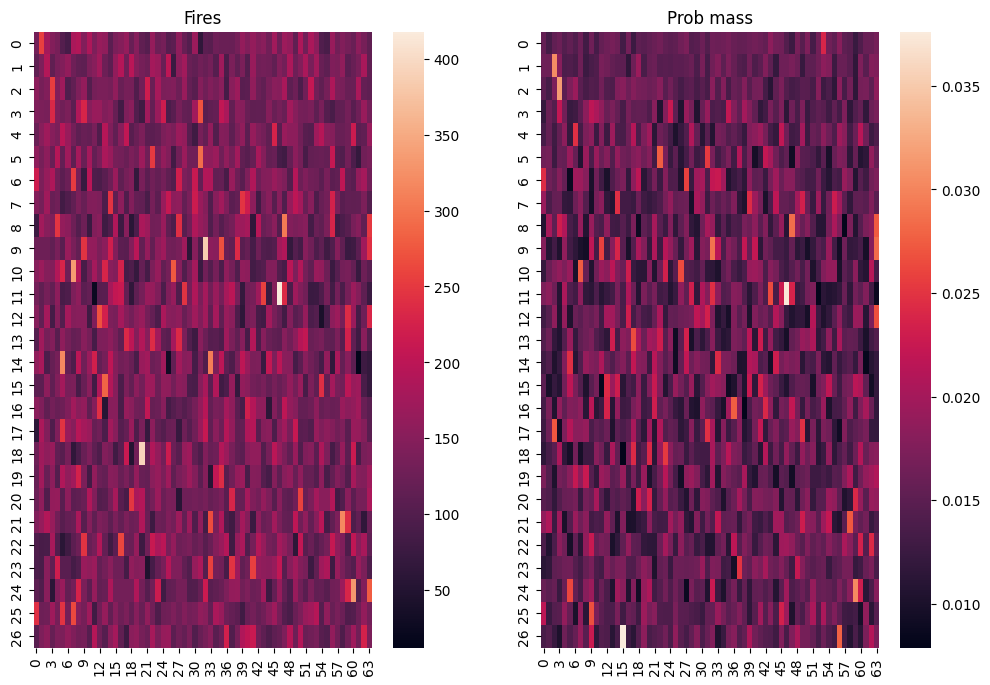

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axs = plt.subplots(ncols=2)
fig.set_size_inches(12, 8)

sns.heatmap(fires, ax=axs[0]).set(title="Fires")
sns.heatmap(list(map(lambda x: x.tolist(), (probs))), ax=axs[1]).set(title="Prob mass")
;

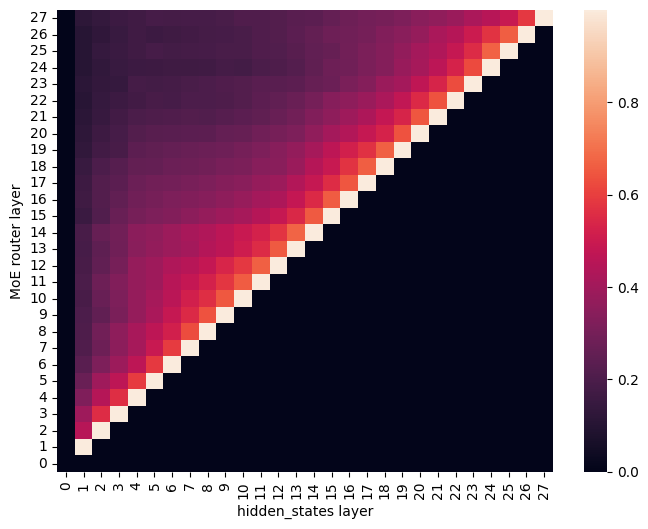

In [78]:
matr = np.mean(matrs, axis=0)
plot_matr_gate_prediction(matr);

In [35]:
for i in range(len(probs)):
    # np.std(probs, axis=1)
    print("Layer {:2d}:".format(i), torch.std(probs[i]).item())


Layer  0: 0.0026178584876604583
Layer  1: 0.003507067420632558
Layer  2: 0.003916235872933558
Layer  3: 0.004147105093175387
Layer  4: 0.004025296642814297
Layer  5: 0.004324983612398528
Layer  6: 0.004191971186663467
Layer  7: 0.003801303980140446
Layer  8: 0.0050625607775218176
Layer  9: 0.00523193674408375
Layer 10: 0.0045176236793253504
Layer 11: 0.005740339966311607
Layer 12: 0.004326292940733763
Layer 13: 0.004817634414877399
Layer 14: 0.004779268999520311
Layer 15: 0.004747835458876983
Layer 16: 0.004443944144964236
Layer 17: 0.004904024942604288
Layer 18: 0.004737486638954286
Layer 19: 0.004327434355051468
Layer 20: 0.0036254296790896767
Layer 21: 0.004804107611697327
Layer 22: 0.004292975507902641
Layer 23: 0.003119688790087589
Layer 24: 0.005128516363005925
Layer 25: 0.004066166909508504
Layer 26: 0.004718900096781657


# Tokens painting (only for mixtral-like)

In [33]:
# CAREFUL RESETS COUNTERS!!!!
SAVE_COUNTERS = True
prompt = "Когда при обработке исключений в Java не выполняется блок finally?"

from termcolor import colored

for layer in model.base_model.layers:
    gate = layer.block_sparse_moe.gate
    gate.counter_probs = []
    gate.counter_fires = []

generate_text(prompt, max_length=40)
print()

tokenized_prompt = tokenizer(prompt).input_ids

colors = ["red", "blue", "yellow", "green", "magenta", "black", "cyan", "light_blue"]


for l in [0, 15, 31]:
    print(f"Layer {l}:")
    
    experts = torch.argmax(model.base_model.layers[l].block_sparse_moe.gate.counter_probs[0], dim=1)
    assert len(experts) == len(tokenized_prompt) 
    
    for idx in range(len(tokenized_prompt)):
        expert = experts[idx]
        color = colors[expert.item()]
        
        token = tokenizer.decode(tokenized_prompt[idx])

        print(colored(tokenizer.decode(tokenized_prompt[idx]), color), end=" ")
        if token == "<0x0A>":
            print()

    for idx in range(len(tokens) - 1):
        
        expert = torch.argmax(model.base_model.layers[l].block_sparse_moe.gate.counter_probs[1 + idx], dim=1)

        color = colors[expert.item()]

        token_id = tokens[idx].item()
        token = tokenizer.decode(token_id)

        print(colored(tokenizer.decode(tokens[idx]), color), end=" ")
        if token == "<0x0A>":
            print()
    
    print()
    print("=====================================")

# print(tokens)

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


prompt=Когда при обработке исключений в Java не выполняется блок finally?

generated_text=

В Java, блок finally всегда выполняется, за

Layer 0:
<s> Ко гда при обра бо т ке и ск лю че ний в Java не вы пол ня ется б лок finally ? <0x0A> 
<0x0A> 
В Java , б лок finally все гда вы пол ня ется , 
Layer 15:
<s> Ко гда при обра бо т ке и ск лю че ний в Java не вы пол ня ется б лок finally ? <0x0A> 
<0x0A> 
В Java , б лок finally все гда вы пол ня ется , 
Layer 31:
<s> Ко гда при обра бо т ке и ск лю че ний в Java не вы пол ня ется б лок finally ? <0x0A> 
<0x0A> 
В Java , б лок finally все гда вы пол ня ется , 


# Mapping tokens to experts

In [108]:
from collections import defaultdict, Counter

prompts = [
    # "Убери в этом тексте все согласные буквы и пробелы между словами. Обычно называемая проблемой культурного релятивизма, в нем упоминается, как этические принципы меняются от одной культуры к другой. Одна из основных существующих этических проблем заключается в том, что не существует единого определения этичного для каждой культуры.",
    # "Кто написал Утро в сосновом бору?",
    # "Древняя Греция известна",
    # 'Переведи предложение с английского на русский. Предложение: "In 2021, wheelchair tennis players Diede de Groot and Dylan Alcott achieved the equivalent wheelchair tennis prize with Paralympic gold". Перевод:',
    # "Простой пример сложения чисел: 2 + (4 + 10)",
    # "Кот на велосипеде может означать",
    # "Что такое ПП?\nА) Парк победы\nБ) Переносной прожектор\nВ) Правильное питание\n\nПравильный ответ:",
    # "Три темы ВКР по славянской мифологии: ",
    # "Пример вульгарной рекламы презервативов на английском языке:",
    # "Когда при обработке исключений в Java не выполняется блок finally?",
    # "Программа на Python, которая складывает три числа",
    # "Dubstep is",
    # "Язык программирования Питон позволяет ",
    # "Мама мыла ",
    # "Short essay on the pros and ",
    # "Всем привет!",
    # "220 вольт это",
    # "Here we go again",
    # "import numpy as np",
    # "Newton is",
    # "Тёплое с мягким",
    # "Я помню чудное мгновенье:",
    # "Donald Trump created"
]

token_pos_to_exp = []
output_tokens = []

reset_counters(model)
LAYER_ID = 1

MAX_LENGTH=90

SAVE_COUNTERS = True
for prompt in prompts:
    gate = get_gate(model.base_model.layers[LAYER_ID])
    gate.counter_probs = []
    
    text = generate_text(prompt, max_length=MAX_LENGTH)
    output_tokens.append(tokenizer(prompt).input_ids + tokenizer(text).input_ids[0:])

    con = torch.concatenate(gate.counter_probs)
    selected_experts = torch.argmax(con, dim=1)    
    token_pos_to_exp.append(selected_experts)


prompt=المجموعات العربية على الانترنِت هي عبارة عن مكتبة 

generated_text=أخرى تقدم مجموعات من الكتب العربية والإسلامية والت
prompt=عماد الدين أبو الفداء إسماعيل بن عمر بن كثير 

generated_text=بن حسن بن محمد بن عبد الله بن محمد بن عبد الله بن م
prompt= المعروف بابن كثير (المتوفى 774 هـ)، هو من أشهر 

generated_text=مؤلفي المقالات السنة والمجلدات الإسلامية. وقد كان م


In [109]:
expert_to_token_pos = [list([list() for _ in range(NUM_EXPERTS)]) for _ in range(len(prompts))] # n_prompts, n_experts, n_assigned_tokens(variable)

for sample_id in range(len(prompts)):
    for pos in range(MAX_LENGTH - 1):
        exp = token_pos_to_exp[sample_id][pos].item()
        expert_to_token_pos[sample_id][exp].append(pos)


In [110]:
expert_to_tokens = [set() for _ in range(NUM_EXPERTS)]

for exp in range(NUM_EXPERTS):
    for sample_id in range(len(prompts)):
        for pos in expert_to_token_pos[sample_id][exp]:
            token = output_tokens[sample_id][pos]
            expert_to_tokens[exp].add(repr(tokenizer.decode(token)))
    
    expert_to_tokens[exp] = sorted(expert_to_tokens[exp])
    

In [111]:
for exp in range(NUM_EXPERTS):
    print(f"exp: {exp} ", end="")
    for token in expert_to_tokens[exp]:
        print(token, end = " ")
        
    print()
    

exp: 0 
exp: 1 
exp: 2 '' 'ا' 'ب' 'ة' 'د' 'ر' 'س' 'ق' 'ل' 'م' 'ن' 'ي' 
exp: 3 'ع' 
exp: 4 
exp: 5 'ب' 'ة' 'س' 'م' 
exp: 6 'ج' 'ِ' 
exp: 7 'ـ' 
exp: 8 '<s>' 
exp: 9 
exp: 10 '<s>' 'أ' 'ب' 
exp: 11 
exp: 12 '.' 'ة' 'ج' 'و' 
exp: 13 
exp: 14 'ك' 'ن' 
exp: 15 'ت' 'ج' 'ح' 'د' 'و' 
exp: 16 'ا' 'ت' 'ي' 
exp: 17 ')' 
exp: 18 
exp: 19 '' 
exp: 20 
exp: 21 'ال' 'ت' 'د' 'ش' 'ع' 
exp: 22 
exp: 23 
exp: 24 
exp: 25 
exp: 26 
exp: 27 '' 'ال' 'ب' 'ت' 'ف' 'م' 
exp: 28 'ك' 'ن' 
exp: 29 
exp: 30 '' 
exp: 31 
exp: 32 '' '7' 'ال' 'ب' 'ث' 'ع' 'م' 
exp: 33 
exp: 34 'ح' 'خ' 'ع' 'ى' 
exp: 35 '' 'ال' 'ت' 'س' 'ن' 'ه' 
exp: 36 
exp: 37 '' 'م' 'ن' 
exp: 38 'إ' 'د' 'ل' 'م' '�' 
exp: 39 'أ' 
exp: 40 '' 'أ' 'ال' 'ر' 'ن' 
exp: 41 
exp: 42 
exp: 43 
exp: 44 'ء' 'ي' 
exp: 45 '4' '7' 
exp: 46 
exp: 47 '(' '،' 
exp: 48 
exp: 49 'ال' 'ح' 
exp: 50 '<s>' 'ب' 'ت' 'د' 'ع' 'ك' 'م' 'ن' 'ه' 'ى' 
exp: 51 'ا' 'ال' 
exp: 52 
exp: 53 'ي' 
exp: 54 'ر' 'ي' 
exp: 55 '' 'ا' 'س' 'ق' 'ل' 'و' 
exp: 56 'إ' 'ت' 'و' 
exp: 57 'ب' 'ع' 'ف' 'ك' '

In [97]:
for exp in range(NUM_EXPERTS):
    print(f"exp: {exp} ", end="")
    for token in expert_to_tokens[exp]:
        print(token, end = " ")
        
    print()
    

exp: 0 
exp: 1 'ا' 
exp: 2 
exp: 3 'ر' 
exp: 4 '' 'أ' 'م' 'ن' 'ى' 'ي' 
exp: 5 
exp: 6 
exp: 7 
exp: 8 
exp: 9 '' '<s>' 'ا' 'ال' 'ب' 'ت' 'ج' 'ر' 'ص' 'ع' 'ق' 'ك' 'ل' 'م' 'ن' 'ه' 'و' 'َ' 'ِ' 'ّ' '�' 
exp: 10 'ر' 
exp: 11 
exp: 12 'ع' 'و' 
exp: 13 
exp: 14 'م' 
exp: 15 '<s>' 
exp: 16 '' 'ة' 
exp: 17 
exp: 18 
exp: 19 '' 'ب' 
exp: 20 'ب' 'ة' 'ت' 'ع' 'ف' 'م' 'ي' 
exp: 21 
exp: 22 
exp: 23 
exp: 24 'ّ' 
exp: 25 
exp: 26 'ع' 
exp: 27 
exp: 28 'ال' 'ل' 
exp: 29 
exp: 30 
exp: 31 
exp: 32 
exp: 33 'ب' 'ة' 
exp: 34 
exp: 35 
exp: 36 
exp: 37 
exp: 38 '' 
exp: 39 
exp: 40 
exp: 41 
exp: 42 
exp: 43 
exp: 44 'ي' 
exp: 45 
exp: 46 
exp: 47 
exp: 48 
exp: 49 
exp: 50 
exp: 51 
exp: 52 'ب' 
exp: 53 
exp: 54 
exp: 55 
exp: 56 'ي' 
exp: 57 
exp: 58 '' 
exp: 59 '' 'ل' 
exp: 60 'ت' 
exp: 61 'ل' 
exp: 62 'َ' 
exp: 63 


In [55]:
for exp in range(NUM_EXPERTS):
    print(f"exp: {exp} ", end="")
    for token in expert_to_tokens[exp]:
        print(token, end = " ")
        
    print()
    

exp: 0 ',' '<s>' 'HL' 'Tr' 'W' 'met' 'ott' 'players' 'в' 'если' 'ла' 'ми' 'ново' 'с' 'своими' 
exp: 1 '' '2' 'the' 'train' 'С' 
exp: 2 '_' 'an' 'and' 'as' 'nt' 'мирова' 'на' 'победы' 
exp: 3 ',' '-' '5' 'Boston' 'Louis' 'United' 'dance' 'own' 'upon' 'бога' 'втором' 'геро' 'делать' 'добиться' 'другой' 'из' 'ност' 'обработки' 'профессиональ' 'роди' 'сы' 'чи' 'яви' 
exp: 4 '' '+' ',' '-' '.' '\n' 'achieved' 'against' 'at' 'has' 'is' 'population' 'schedule' 'will' 'вля' 'ждан' 'жем' 'жением' 'их' 'контексте' 'на' 'наде' 'результа' 'с' 'склады' 
exp: 5 ',' 'Here' '\n' 'music' 'В' 'вам' 'вом' 'вы' 'ко' 'ну' 'о' 'с' 'том' 'этом' 
exp: 6 ',' '<s>' 'Java' '\n' '_' 'ings' 'Кто' 'П' 'Что' 'ам' 'во' 'ет' 'и' 'льный' 'льт' 'м' 'ру' 'такое' 'тро' 'что' 'это' 
exp: 7 '".' '"?' '' ',' '.' '<s>' '\n' 'ally' 'and' 'for' 'including' 'of' 'open' 'released' 'the' 'В' 'У' 'в' 'дней' 'ем' 'й' 'к' 'мирова' 'написа' 'ологи' 'пер' 'рассказать' 'тите' 'числа' 'что' '’' 
exp: 8 ',' '3' 'Reg' 'Scal' '\n' '_' 'as' 

# Weights distances (outdated)

In [10]:
CHECKPOINT_PATH_12k = "/home/jovyan/vmamedov/checkpoints_prod/giga_mix_8x7b_8k/480k_warmup5000__wd1e-06__lr2e-05__aux0.01__jitter0.001__zloss0.0__rank0.0/12k_hf/"
CHECKPOINT_PATH_148k = "/home/jovyan/vmamedov/checkpoints_prod/giga_mix_8x7b_8k/480k_warmup5000__wd1e-06__lr2e-05__aux0.01__jitter0.001__zloss0.0__rank0.0/148k_hf/"

In [11]:
model_12k = AutoModelForCausalLM.from_pretrained(CHECKPOINT_PATH_12k, device_map="cpu")
model_12k.eval()

Loading checkpoint shards:   0%|          | 0/31 [00:00<?, ?it/s]/home/jovyan/.mlspace/envs/gigachat_7b_moe/lib/python3.9/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
Loading checkpoint shards: 100%|██████████| 31/31 [00:03<00:00,  8.81it/s]


MixtralForCausalLM(
  (model): MixtralModel(
    (embed_tokens): Embedding(42000, 4096, padding_idx=2)
    (layers): ModuleList(
      (0-31): 32 x MixtralDecoderLayer(
        (self_attn): MixtralAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (rotary_emb): MixtralRotaryEmbedding()
        )
        (block_sparse_moe): MixtralSparseMoeBlock(
          (gate): Linear(in_features=4096, out_features=8, bias=False)
          (experts): ModuleList(
            (0-7): 8 x MixtralBLockSparseTop2MLP(
              (w1): Linear(in_features=4096, out_features=11008, bias=False)
              (w2): Linear(in_features=11008, out_features=4096, bias=False)
              (w3): Linear(in_features=4096, out_features=11008, bias=

In [51]:
model_148k.model.layers[0].block_sparse_moe.experts[0].w1.weight.size()

torch.Size([11008, 4096])

In [66]:
model_148k = AutoModelForCausalLM.from_pretrained(CHECKPOINT_PATH_148k, device_map="cpu", load_in_8bit=True)
model_148k.eval()

Loading checkpoint shards: 100%|██████████| 31/31 [03:00<00:00,  5.82s/it]


MixtralForCausalLM(
  (model): MixtralModel(
    (embed_tokens): Embedding(42000, 4096, padding_idx=2)
    (layers): ModuleList(
      (0-31): 32 x MixtralDecoderLayer(
        (self_attn): MixtralAttention(
          (q_proj): Linear8bitLt(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear8bitLt(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear8bitLt(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear8bitLt(in_features=4096, out_features=4096, bias=False)
          (rotary_emb): MixtralRotaryEmbedding()
        )
        (block_sparse_moe): MixtralSparseMoeBlock(
          (gate): Linear8bitLt(in_features=4096, out_features=8, bias=False)
          (experts): ModuleList(
            (0-7): 8 x MixtralBLockSparseTop2MLP(
              (w1): Linear8bitLt(in_features=4096, out_features=11008, bias=False)
              (w2): Linear8bitLt(in_features=11008, out_features=4096, bias=False)
              (w3): Linear8b

In [74]:
model_12k.model.layers[0].block_sparse_moe.experts[i].w1


Parameter containing:
Parameter(Int8Params([[ 0.0154, -0.0019, -0.0241,  ...,  0.0488, -0.0209,  0.0146],
            [-0.0125,  0.0084,  0.0098,  ...,  0.0152, -0.0290,  0.0131],
            [-0.0054,  0.0321, -0.0077,  ...,  0.0188,  0.0289,  0.0045],
            ...,
            [ 0.0027,  0.0354, -0.0253,  ..., -0.0352,  0.0149, -0.0144],
            [-0.0013,  0.0105,  0.0471,  ...,  0.0004,  0.0088,  0.0013],
            [ 0.0038, -0.0072,  0.0261,  ...,  0.0041, -0.0229,  0.0068]],
           dtype=torch.float16))

In [ ]:
cos_sim_list = []
for i in range(8): 
    for j in range(i + 1, 8):
        a = model_12k.model.layers[0].block_sparse_moe.experts[i].w1.weight
        b = model_12k.model.layers[0].block_sparse_moe.experts[j].w1.weight
  
        # print(torch.nn.functional.cosine_similarity(a.view(-1), b.view(-1), dim=0))
        # break
    # break
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
        cos_sim_list.append(torch.nn.functional.cosine_similarity(a.view(-1), b.view(-1), dim=0))

# np.mean(cos_sim_list)

In [85]:
cos_sim_list = []
for i in range(8): 
    for j in range(i + 1, 8):
        a = model_12k.model.layers[-1].block_sparse_moe.experts[i].w1.weight
        b = model_12k.model.layers[-1].block_sparse_moe.experts[j].w1.weight
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
        cos_sim_list.append(torch.nn.functional.cosine_similarity(a.view(-1), b.view(-1), dim=0))

np.mean(cos_sim_list)

0.813

In [84]:
cos_sim_list = []
for i in range(8): 
    for j in range(i + 1, 8):
        a = model_12k.model.layers[0].block_sparse_moe.experts[i].w1.weight
        b = model_12k.model.layers[0].block_sparse_moe.experts[j].w1.weight
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
        cos_sim_list.append(torch.nn.functional.cosine_similarity(a.view(-1), b.view(-1), dim=0))

np.mean(cos_sim_list)

0.814

In [77]:
cos_sim_list = []
for i in range(8): 
    for j in range(i + 1, 8):
        a = model_148k.model.layers[0].block_sparse_moe.experts[i].w1.weight
        b = model_148k.model.layers[0].block_sparse_moe.experts[j].w1.weight
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
        cos_sim_list.append(torch.nn.functional.cosine_similarity(a.view(-1), b.view(-1), dim=0))

np.mean(cos_sim_list)

0.796

In [ ]:
#

In [37]:
for layer_num in range(32): 
    cos_sim_list = []
    for i in range(8):
        a = model_12k.model.layers[layer_num].block_sparse_moe.experts[i].w1.weight.detach()
        b = model_148k.model.layers[layer_num].block_sparse_moe.experts[i].w1.weight.detach()
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
        cos_sim_list.append(torch.nn.functional.cosine_similarity(a.view(-1), b.view(-1), dim=0))
    print("Layer {:2d}:".format(layer_num), np.mean(cos_sim_list))


Layer  0: 0.9928248
Layer  1: 0.98590446
Layer  2: 0.98119664
Layer  3: 0.9788539
Layer  4: 0.97775865
Layer  5: 0.97664034
Layer  6: 0.97665143
Layer  7: 0.97593045
Layer  8: 0.9757149
Layer  9: 0.97563654
Layer 10: 0.97440886
Layer 11: 0.9734864
Layer 12: 0.9721874
Layer 13: 0.9711511
Layer 14: 0.9709621
Layer 15: 0.9708143
Layer 16: 0.97013634
Layer 17: 0.97015345
Layer 18: 0.97170305
Layer 19: 0.97217125
Layer 20: 0.9726962
Layer 21: 0.9730005
Layer 22: 0.97334003
Layer 23: 0.972996
Layer 24: 0.9720074
Layer 25: 0.9711769
Layer 26: 0.9704006
Layer 27: 0.9700935
Layer 28: 0.9702513
Layer 29: 0.9709954
Layer 30: 0.97350174
Layer 31: 0.97586566


In [38]:
for layer_num in range(32): 
    cos_sim_list = []
    for i in range(8):
        for j in range(i + 1, 8):
            a = model_148k.model.layers[layer_num].block_sparse_moe.experts[i].w1.weight.detach()
            b = model_148k.model.layers[layer_num].block_sparse_moe.experts[j].w1.weight.detach()
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
            cos_sim_list.append(torch.nn.functional.cosine_similarity(a.view(-1), b.view(-1), dim=0))
    print("Layer {:2d}:".format(layer_num), np.mean(cos_sim_list))


Layer  0: 0.98051184
Layer  1: 0.9660178
Layer  2: 0.9567537
Layer  3: 0.9523215
Layer  4: 0.95018196
Layer  5: 0.94809407
Layer  6: 0.94830954
Layer  7: 0.94702286
Layer  8: 0.9468106
Layer  9: 0.9468709
Layer 10: 0.9445351
Layer 11: 0.9426555
Layer 12: 0.9400801
Layer 13: 0.93826395
Layer 14: 0.93789035
Layer 15: 0.9372285
Layer 16: 0.93530226
Layer 17: 0.93470794
Layer 18: 0.93706924
Layer 19: 0.93736535
Layer 20: 0.9377904
Layer 21: 0.93759793
Layer 22: 0.93796605
Layer 23: 0.9369394
Layer 24: 0.93448526
Layer 25: 0.9326025
Layer 26: 0.93077534
Layer 27: 0.9302974
Layer 28: 0.93079627
Layer 29: 0.9330249
Layer 30: 0.9394453
Layer 31: 0.9500974


In [46]:
for layer_num in range(32): 
    l2_norm_list = []
    l2_one_exp_matr_norm_list = []
    for i in range(8):
        for j in range(i + 1, 8):
            a = model_148k.model.layers[layer_num].block_sparse_moe.experts[i].w1.weight.detach()
            b = model_148k.model.layers[layer_num].block_sparse_moe.experts[j].w1.weight.detach()
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
        l2_norm_list.append(torch.norm(a - b))
        l2_one_exp_matr_norm_list.append(torch.norm(a))
    print("Layer {:2d}:".format(layer_num), "{:5f}".format(np.mean(l2_norm_list)), "{:5f}".format(np.mean(l2_one_exp_matr_norm_list)), np.mean(l2_norm_list) / np.mean(l2_one_exp_matr_norm_list))


Layer  0: 26.444252 118.132889 0.22385174
Layer  1: 40.057808 141.580170 0.28293374
Layer  2: 46.471523 147.220596 0.3156591
Layer  3: 49.174789 149.827301 0.32820982
Layer  4: 50.459965 151.373306 0.33334783
Layer  5: 51.812847 152.127991 0.3405872
Layer  6: 52.605125 154.632950 0.3401935
Layer  7: 53.754761 155.705017 0.3452346
Layer  8: 54.214413 156.972687 0.34537482
Layer  9: 54.587784 158.378601 0.34466642
Layer 10: 55.560822 158.133362 0.3513542
Layer 11: 56.655746 158.717499 0.35695967
Layer 12: 56.937897 156.528641 0.36375386
Layer 13: 57.503128 155.373505 0.3700961
Layer 14: 57.509995 155.033340 0.37095243
Layer 15: 57.814606 154.514709 0.37416893
Layer 16: 57.862331 154.085327 0.37552136
Layer 17: 58.032791 153.601501 0.37781397
Layer 18: 58.273689 154.786987 0.37647668
Layer 19: 57.499157 154.926208 0.371139
Layer 20: 57.355659 155.383347 0.3691236
Layer 21: 57.409340 155.847916 0.3683677
Layer 22: 58.134113 156.578369 0.37127805
Layer 23: 58.325596 157.017120 0.3714601
Lay

In [ ]:
for layer_num in range(32): 
    l2_norm_list = []
    for i in range(8):
        for j in range(i + 1, 8):
            a = model_12k.model.layers[layer_num].block_sparse_moe.experts[i].w1.weight.detach()
            b = model_148k.model.layers[layer_num].block_sparse_moe.experts[j].w1.weight.detach()
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
        l2_norm_list.append(torch.norm(a - b))
    print("Layer {:2d}:".format(layer_num), np.mean(l2_norm_list))


In [39]:
for layer_num in range(32): 
    cos_sim_list = []
    for i in range(8):
        for j in range(i + 1, 8):
            a = model_12k.model.layers[layer_num].block_sparse_moe.experts[i].w1.weight.detach()
            b = model_12k.model.layers[layer_num].block_sparse_moe.experts[j].w1.weight.detach()
        # b = params0_148k[f"model.layers.0.block_sparse_moe.experts.{j}.w1.weight"]
            cos_sim_list.append(torch.nn.functional.cosine_similarity(a.view(-1), b.view(-1), dim=0))
    print("Layer {:2d}:".format(layer_num), np.mean(cos_sim_list))


Layer  0: 1.0038236
Layer  1: 1.0037601
Layer  2: 1.0031185
Layer  3: 1.0028588
Layer  4: 1.0027138
Layer  5: 1.0026486
Layer  6: 1.0026481
Layer  7: 1.0026228
Layer  8: 1.0026089
Layer  9: 1.0026308
Layer 10: 1.0026437
Layer 11: 1.002618
Layer 12: 1.0026747
Layer 13: 1.00271
Layer 14: 1.0027316
Layer 15: 1.0027019
Layer 16: 1.0026838
Layer 17: 1.0026565
Layer 18: 1.0026816
Layer 19: 1.0025756
Layer 20: 1.0025398
Layer 21: 1.0024451
Layer 22: 1.002373
Layer 23: 1.002303
Layer 24: 1.0022111
Layer 25: 1.002128
Layer 26: 1.0020989
Layer 27: 1.0021
Layer 28: 1.0021055
Layer 29: 1.0022392
Layer 30: 1.0025241
Layer 31: 1.0032033


# TEST

In [127]:
!ls /home/jovyan/elluran/moe/one-button-metrics/button/data/datasets

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


__init__.py		 fuse_calculator.jsonl	 mmlu-en.jsonl
__pycache__		 fuse_text2image.jsonl	 mmlu-ru.jsonl
b2c.jsonl		 human-eval.jsonl	 rubq.jsonl
bsp-long-context.jsonl	 law-with-context.jsonl  winogrande.jsonl
bsp-short-context.jsonl  law.jsonl


In [129]:
import pandas as pd


# with open("/mmlu-en.jsonl") as f:
    # mmlu_json = .load) 

rubq_json = pd.read_json("/home/jovyan/elluran/moe/one-button-metrics/button/data/datasets/rubq.jsonl", lines=True)

In [28]:
import pandas as pd


# with open("/mmlu-en.jsonl") as f:
    # mmlu_json = .load) 

mmlu_json = pd.read_json("/home/jovyan/elluran/moe/one-button-metrics/button/data/datasets/mmlu-en.jsonl", lines=True)

In [29]:
mmlu_json["context"][0]

'(Z,*) is a group with a*b = a+b+1 for all a, b in Z. The inverse of a is\nChoose an answer from the options:\n[A] 0\n[B] -2\n[C] a-2\n[D] (2+a)*-1'

In [30]:
idx = 15
prompt = mmlu_json["context"][idx]
tokens = tokenizer(prompt).input_ids

detokenized = tokenizer.decode(tokens[:6])
detokenized

print(repr(detokenized))
print(repr(mmlu_json["context"][idx]))
generate_text(detokenized, max_length=100)

'<s>Find the characteristic of the'
'Find the characteristic of the ring Z_3 x Z_3.\nChoose an answer from the options:\n[A] 0\n[B] 3\n[C] 12\n[D] 30'
prompt=<s>Find the characteristic of the

generated_text= following matrix:

$$\begin{bmatrix} 1 & -2 \\ \frac{-3}{4}& -\frac {5}{6}\\0&-\frac {-7}{8}\end{bmatrix}$$</s>


' following matrix:\n\n$$\\begin{bmatrix} 1 & -2 \\\\ \\frac{-3}{4}& -\\frac {5}{6}\\\\0&-\\frac {-7}{8}\\end{bmatrix}$$</s>'

In [121]:
mmlu_json

,subset,answer,context
0,abstract_algebra,[D],"(Z,*) is a group with a*b = a+b+1 for all a, b..."
1,abstract_algebra,[C],"A subset H of a group (G,*) is a group if\nCho..."
2,abstract_algebra,[A],Compute the product in the given ring. (12)(16...
3,abstract_algebra,[C],"Compute the product in the given ring. (2,3)(3..."
4,abstract_algebra,[D],Compute the product in the given ring. (20)(-8...
...,...,...,...
14010,world_religions,[B],Who is the founder of Sikhism?\nChoose an answ...
14011,world_religions,[B],Who is the woman mystic who exemplified the al...
14012,world_religions,[C],Who was the first significant anchorite hermit...
14013,world_religions,[A],Why is Mahavira a significant person in the Ja...


In [31]:
prompt = "To Keep Reading This"
tokens = tokenizer(prompt).input_ids

# detokenized = tokenizer.decode(tokens[:6])
# detokenized

# print(repr(detokenized))
# print(repr(mmlu_json["context"][idx]))
print(prompt)
generate_text(prompt, max_length=100)

To Keep Reading This
prompt=To Keep Reading This

generated_text= Article, Please Register at the Top Right Corner of this page
To keep reading articles on our site for free please register to your right. It's quick and easy!</s>


" Article, Please Register at the Top Right Corner of this page\nTo keep reading articles on our site for free please register to your right. It's quick and easy!</s>"

In [35]:
prompt = "Приобретение и распространение"
tokens = tokenizer(prompt).input_ids

# detokenized = tokenizer.decode(tokens[:6])
# detokenized

# print(repr(detokenized))
# print(repr(mmlu_json["context"][idx]))
print(prompt)
generate_text(prompt, max_length=100)

Приобретение и распространение
prompt=Приобретение и распространение

generated_text=наркотиков - это преступление, которое карается по всей строгости закона. Но в последнее время участились случаи употребления запрещенных веществ несовершеннолетними лицами.
В связи с этим 15 марта на базе МБОУ "СОШ №2" г. Суровикино прошел круглый стол для учащихся старших классов под названием: "Наркотики-это смерть". В мероприятии приняли участие сотрудники ОМВД России


'наркотиков - это преступление, которое карается по всей строгости закона. Но в последнее время участились случаи употребления запрещенных веществ несовершеннолетними лицами.\nВ связи с этим 15 марта на базе МБОУ "СОШ №2" г. Суровикино прошел круглый стол для учащихся старших классов под названием: "Наркотики-это смерть". В мероприятии приняли участие сотрудники ОМВД России'